<p class="lead">Unit 1 ended with a sentence worth repeating: <em>a molecule is a labelled graph</em>. This unit takes that sentence literally. We make the graph explicit — nodes, edges, labels, the adjacency matrix a computer scientist already knows — and then we use it to understand the one fact about molecules that most surprises newcomers: two molecules can have exactly the same formula, even the same bonds, and still be different substances with different smells, different activities, and, in one infamous case, the difference between a medicine and a birth defect. That phenomenon is <strong>isomerism</strong>, and understanding it precisely is the difference between a cheminformatics pipeline that works and one that silently confuses two compounds. By the end you will build a molecule's adjacency matrix by hand and confirm it in code, distinguish constitution from configuration from conformation, find a drug's chiral centres and enumerate every stereoisomer, and explain why the string you fetch from a database is only a partial description of the thing it names.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Represent a molecule as a labelled graph and build its adjacency, bond-order and degree structures in RDKit, connecting each to the graph vocabulary of computer science.</li>
<li>Distinguish <strong>constitution</strong>, <strong>configuration</strong> and <strong>conformation</strong> and give a concrete molecular example of each.</li>
<li>Explain constitutional isomers and stereoisomers, and why molecules with the same formula need not be the same graph.</li>
<li>Explain chirality, enantiomers and diastereomers; assign R/S by the Cahn–Ingold–Prelog rules on paper and confirm with RDKit.</li>
<li>Recount the thalidomide case and state precisely why two enantiomers can have opposite biological effects.</li>
<li>Enumerate the stereoisomers of a chiral drug and reason about the 2<sup>n</sup> growth; distinguish cis/trans (E/Z), tautomers and resonance.</li>
<li>Explain why one 2-D graph corresponds to many 3-D conformers, and generate a few for a small molecule.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly once, running each code cell as you reach it and reading the printed output before moving on; then re-run cells while changing one thing at a time (a SMILES string, an atom index) to see what moves. Green <strong>chemistry boxes</strong> define each chemical term the first time it appears, usually through an analogy a programmer already has. The only library you must install in Google Colab is RDKit (<code>!pip install rdkit</code>); NumPy, pandas and matplotlib are already there. This unit uses no network and no downloads — every molecule is a short SMILES string written directly in the cell.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, AllChem, rdMolDescriptors, rdMolAlign, rdMolTransforms, rdCIPLabeler
from rdkit.Chem.EnumerateStereoisomers import EnumerateStereoisomers
from rdkit.Chem.MolStandardize import rdMolStandardize
rdkit.RDLogger.DisableLog("rdApp.*")          # silence RDKit valence/stereo chatter in this teaching notebook
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("RDKit", rdkit.__version__, "| this unit turns molecules into graphs and back")

RDKit 2026.03.4 | this unit turns molecules into graphs and back


## 1. A molecule is a labelled graph — made precise

A **graph** in the computer-science sense is a set of **nodes** (vertices) joined by **edges**. A molecule maps onto this structure exactly: each atom is a node, each covalent bond is an edge. What makes a molecule a *labelled* graph is that the nodes and edges carry data — a node's label is its chemical element (and its charge, and whether it is aromatic); an edge's label is the **bond order** (single, double, triple, aromatic). The whole of cheminformatics is, in a real sense, algorithms on this labelled graph<sup class="c"><a href="#r1">[1]</a></sup>, and the idea is old: chemists were applying graph theory to molecules decades before "cheminformatics" had a name<sup class="c"><a href="#r2">[2]</a></sup>.

<div class="box bridge"><h4>Chemistry box — the words chemists use for graph parts</h4>
<p>Chemists rarely say "node" or "edge". A node is an <strong>atom</strong>; an edge is a <strong>bond</strong>. A node's degree (its number of edges) is the atom's number of bonded neighbours — and because of <em>valence</em> (Unit 1: C forms 4 bonds, N 3, O 2, H 1) this degree is small and capped. A cycle in the graph is a <strong>ring</strong>. A connected component is a <strong>molecule</strong> (a structure with two disconnected components is a salt or a mixture — two molecules in one record). Translating freely between the two vocabularies is the single most useful habit in this course.</p></div>

Let us make the graph tangible by walking it. The cell below takes caffeine — the molecule we will use throughout this unit — and lists its atoms (nodes) with their labels and degrees, then its bonds (edges) with their orders. This is the same object every later method consumes.

In [2]:
# Caffeine as a labelled graph: nodes (atoms) with labels, then edges (bonds) with labels.
caf = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
print("caffeine:", caf.GetNumAtoms(), "nodes (heavy atoms),", caf.GetNumBonds(), "edges (bonds)\n")
node_rows = [(a.GetIdx(), a.GetSymbol(), a.GetDegree(), a.GetTotalNumHs(),
              a.GetFormalCharge(), a.GetIsAromatic()) for a in caf.GetAtoms()]
nodes = pd.DataFrame(node_rows, columns=["idx", "element", "degree", "implicit_H", "charge", "aromatic"])
print("element counts:", nodes.element.value_counts().to_dict(),
      "| aromatic nodes:", int(nodes.aromatic.sum()))
edge_rows = [(b.GetBeginAtomIdx(), b.GetEndAtomIdx(), str(b.GetBondType())) for b in caf.GetBonds()]
print("first six edges (begin, end, order):", edge_rows[:6])
nodes.head(6)

caffeine: 14 nodes (heavy atoms), 15 edges (bonds)

element counts: {'C': 8, 'N': 4, 'O': 2} | aromatic nodes: 9
first six edges (begin, end, order): [(0, 1, 'SINGLE'), (1, 2, 'AROMATIC'), (2, 3, 'AROMATIC'), (3, 4, 'AROMATIC'), (4, 5, 'AROMATIC'), (5, 6, 'AROMATIC')]


,idx,element,degree,implicit_H,charge,aromatic
0,0,C,1,3,0,False
1,1,N,3,0,0,True
2,2,C,2,1,0,True
3,3,N,2,0,0,True
4,4,C,3,0,0,True
5,5,C,3,0,0,True


The printout is the whole graph in two tables: fourteen nodes (two oxygens, three carbons outside rings as methyls, and the ring atoms), each with a degree that never exceeds 3 here, and fifteen edges whose labels are a mix of `SINGLE`, `DOUBLE` and `AROMATIC`. Notice the two extra things a *chemical* graph carries beyond a plain one: every node knows how many hydrogens hang off it implicitly (the `implicit_H` column — Unit 1's valence bookkeeping) and whether it is aromatic. These labels are exactly the atom and bond *features* that, attached to the graph, become the input of the graph-neural-network methods we meet in Block E<sup class="c"><a href="#r6">[6]</a></sup>.

## 2. The adjacency matrix — a molecule as the object you already know

The most familiar encoding of a graph is the **adjacency matrix** $A$: an $n\times n$ array for $n$ nodes, where $A_{ij}=1$ if nodes $i$ and $j$ are bonded and $0$ otherwise. For an undirected graph — and a molecule is undirected, a bond has no direction — $A$ is symmetric, and its diagonal is zero (an atom is not bonded to itself). The sum of row $i$ is the degree of node $i$. This is the bridge between chemistry and every graph algorithm you already know.

Because this matrix is the heart of the unit, we build it **by hand** for caffeine first, then confirm it with RDKit<sup class="c"><a href="#r7">[7]</a></sup>. To do that we need a fixed atom numbering, so the cell below redraws caffeine with each atom's index printed on it. Read the indices off the picture; we will refer to them throughout.

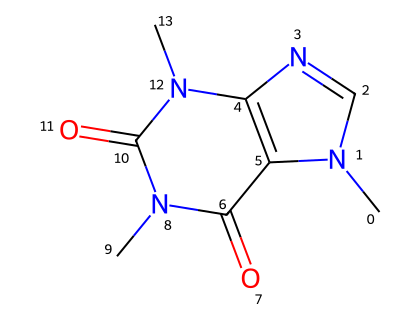

In [3]:
# Draw caffeine with atom indices so we can build its adjacency matrix by hand.
caf_idx = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
for a in caf_idx.GetAtoms():
    a.SetProp("atomNote", str(a.GetIdx()))      # print the index next to each atom
Draw.MolToImage(caf_idx, size=(420, 320))

<p class="caption"><b>Figure 1.</b> Caffeine with RDKit's atom indices (0–13) written beside each heavy atom. Atom 0, 9 and 13 are the three N-methyl carbons; 7 and 11 are the two carbonyl oxygens; the rest form the fused two-ring (purine) core. Hydrogens are implicit and carry no index. We now read the bonds straight off this picture and assemble the adjacency matrix with nothing but a pencil.</p>

### 2.1 Building the matrix by hand

From the drawing, caffeine's fifteen bonds (edges) are, as unordered pairs of atom indices:

<div class="eq">
0–1, 1–2, 2–3, 3–4, 4–5, 5–6, 6–7, 6–8, 8–9, 8–10, 10–11, 10–12, 12–13, 5–1, 12–4
</div>

The adjacency matrix is then mechanical: start with a 14×14 grid of zeros, and for every pair $i$–$j$ in the list write a 1 at position $(i,j)$ **and** at $(j,i)$ (symmetry). For example, atom 1 (a ring nitrogen) appears in the pairs 0–1, 1–2 and 5–1, so row 1 has 1s in columns 0, 2 and 5 — degree 3, matching the table in §1. Atom 0 (a methyl carbon) appears only in 0–1, so row 0 has a single 1 in column 1 — degree 1, a leaf of the graph. The cell below carries out exactly this pencil procedure in code and then checks it against RDKit's own `GetAdjacencyMatrix`.

In [4]:
# Build caffeine's adjacency matrix BY HAND from the edge list, then confirm with RDKit.
edges = [(0,1),(1,2),(2,3),(3,4),(4,5),(5,6),(6,7),(6,8),
         (8,9),(8,10),(10,11),(10,12),(12,13),(5,1),(12,4)]
n = caf.GetNumAtoms()
A_hand = np.zeros((n, n), dtype=int)
for i, j in edges:
    A_hand[i, j] = 1
    A_hand[j, i] = 1                              # symmetry: a bond is undirected
A_rdkit = Chem.GetAdjacencyMatrix(caf)
print("hand-built matches RDKit:", bool(np.array_equal(A_hand, A_rdkit)))
print("symmetric:", bool((A_hand == A_hand.T).all()), "| diagonal all zero:", bool((np.diag(A_hand) == 0).all()))
print("row sums (= node degrees):", A_hand.sum(1).tolist())
print("row 0 (methyl):", A_hand[0].tolist())
print("row 1 (ring N):", A_hand[1].tolist())

hand-built matches RDKit: True
symmetric: True | diagonal all zero: True
row sums (= node degrees): [1, 3, 2, 2, 3, 3, 3, 1, 3, 1, 3, 1, 3, 1]
row 0 (methyl): [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
row 1 (ring N): [1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]


The hand-built matrix is identical to RDKit's (`True`), it is symmetric with a zero diagonal, and its row sums reproduce the degree sequence from §1. Row 0 has a single 1 (the methyl leaf); row 1 has three (the ring nitrogen). You have now constructed the central data structure of cheminformatics from a picture, by hand, and verified it — exactly the kind of check you can redo on paper for any small molecule. The cell below visualises both the plain adjacency matrix and the **bond-order–weighted** version, where double bonds carry 2 and aromatic bonds 1.5.

weighted-matrix non-zero values: [1.0, 1.5, 2.0]


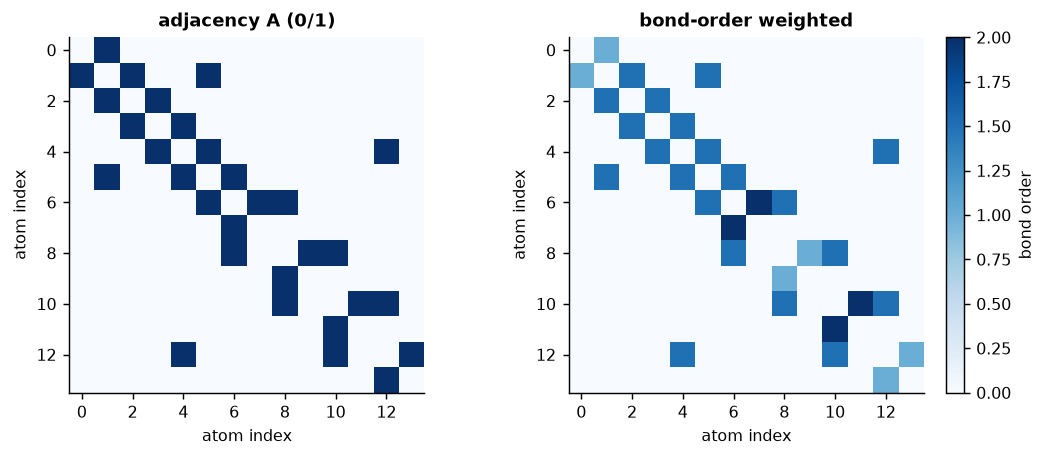

In [5]:
# Plain adjacency (0/1) and bond-order-weighted adjacency (single=1, aromatic=1.5, double=2).
A = Chem.GetAdjacencyMatrix(caf)
Aw = Chem.GetAdjacencyMatrix(caf, useBO=True)        # useBO: entries are bond orders
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, M, t in zip(axes, [A, Aw], ["adjacency A (0/1)", "bond-order weighted"]):
    im = ax.imshow(M, cmap="Blues"); ax.set_title(t)
    ax.set_xlabel("atom index"); ax.set_ylabel("atom index")
fig.colorbar(im, ax=axes[1], fraction=0.046, label="bond order")
print("weighted-matrix non-zero values:", sorted(set(Aw[Aw > 0].tolist())))
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Caffeine as an adjacency matrix. Left: the 0/1 form — symmetric, sparse (only 30 of 196 entries are non-zero), with the two off-diagonal bands that mark the fused rings. Right: the bond-order–weighted form, whose non-zero entries are exactly {1.0, 1.5, 2.0} (single, aromatic, double) as the printout confirms. The weighted matrix carries strictly more information than the plain one — it is the plain adjacency plus the edge labels — and it is one short step from the feature matrices that message-passing networks consume. A molecular graph is <em>sparse</em> and <em>low-degree</em> because valence caps every row sum, which is precisely why cheminformatics algorithms over these graphs are cheap.</p>

<div class="box warn"><h4>The atom numbering is arbitrary — the molecule is not</h4>
<p>RDKit's indices 0–13 came from the order atoms appeared in the SMILES string, not from any canonical chemical rule. A different but equivalent SMILES would give a different numbering and hence a different-looking adjacency matrix for the <em>same</em> molecule — the matrices are related by a permutation (relabelling the nodes). Deciding on <em>one</em> canonical ordering so that identical molecules get identical matrices is the problem of <strong>canonicalisation</strong>, solved historically by the Morgan algorithm<sup class="c"><a href="#r5">[5]</a></sup> and by modern canonical-ranking implementations<sup class="c"><a href="#r26">[26]</a></sup>; it is the subject of Unit 3. For now, just hold the warning: an adjacency matrix depends on a node ordering, a molecule does not.</p></div>

Seeing the matrix is one thing; seeing the graph it encodes beside the chemist's drawing cements the translation. The cell lays out caffeine's atoms using RDKit's 2-D coordinates and draws the edges itself — a hand-rolled graph plot — next to the conventional structure, so you can watch the same fourteen nodes and fifteen edges appear in both renderings.

one object, two renderings: 14 nodes and 15 edges


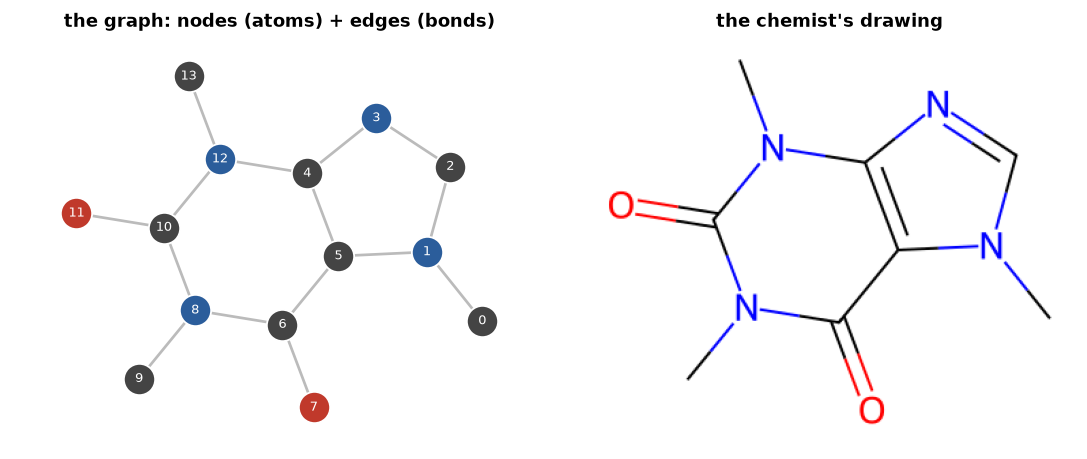

In [6]:
# The molecular graph (drawn by hand from nodes + edges) beside RDKit's chemical drawing.
from rdkit.Chem import rdDepictor
m = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C"); rdDepictor.Compute2DCoords(m)
conf = m.GetConformer()
pos = {a.GetIdx(): (conf.GetAtomPosition(a.GetIdx()).x, conf.GetAtomPosition(a.GetIdx()).y) for a in m.GetAtoms()}
col = {"C": "#444", "N": "#2b5d9b", "O": "#c0392b"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.6))
for b in m.GetBonds():                                     # edges
    i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
    ax1.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]], "-", color="#bbb", zorder=1)
for idx, (x, y) in pos.items():                            # nodes
    s = m.GetAtomWithIdx(idx).GetSymbol()
    ax1.scatter(x, y, s=300, color=col.get(s, "#555"), zorder=2, edgecolors="w")
    ax1.text(x, y, str(idx), color="w", ha="center", va="center", fontsize=7, zorder=3)
ax1.set_title("the graph: nodes (atoms) + edges (bonds)"); ax1.axis("equal"); ax1.axis("off")
ax2.imshow(np.array(Draw.MolToImage(m, size=(360, 300)))); ax2.axis("off"); ax2.set_title("the chemist's drawing")
print("one object, two renderings:", m.GetNumAtoms(), "nodes and", m.GetNumBonds(), "edges")
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Caffeine as a hand-drawn node-and-edge graph (left; nitrogen blue, oxygen red, carbon grey, with the same indices as Figure 1) beside RDKit's conventional chemical drawing (right). They are the same object: the drawing <em>is</em> a graph layout with chemistry-aware styling. Once you see a structure this way, every operation in the course — substructure search, fingerprinting, scaffold extraction, message passing — reads as a familiar graph algorithm.</p>

### 2.2 Graph invariants: numbers that do not depend on the numbering

Because the numbering is arbitrary, the quantities we trust are **graph invariants** — numbers that stay the same under any relabelling of the nodes. The degree sequence (the sorted list of row sums) is one. Two more that chemists invented long before modern ML are the number of independent rings and simple **topological indices** that summarise the whole graph in a single number<sup class="c"><a href="#r3">[3]</a></sup>. The oldest, the Wiener index, is just the sum of shortest-path lengths between all pairs of atoms and correlates with physical properties like boiling point<sup class="c"><a href="#r4">[4]</a></sup>. The cell computes a few invariants for caffeine directly from the graph.

In [7]:
# Graph invariants of caffeine, computed from the graph (independent of atom numbering).
A = Chem.GetAdjacencyMatrix(caf)
deg_seq = sorted(A.sum(1).tolist())
V, E = caf.GetNumAtoms(), caf.GetNumBonds()
# independent rings = cyclomatic number = E - V + (connected components); caffeine is one component
rings_cyclomatic = E - V + 1
# Wiener index = sum over all pairs of the shortest-path (topological) distance
Dmat = Chem.GetDistanceMatrix(caf)
wiener = int(Dmat[np.triu_indices(V, k=1)].sum())
print("degree sequence:", deg_seq)
print("independent rings (E - V + 1):", rings_cyclomatic, "| RDKit ring count:", rdMolDescriptors.CalcNumRings(caf))
print("graph diameter (longest shortest path):", int(Dmat.max()), "bonds")
print("Wiener index (sum of all-pairs distances):", wiener)

degree sequence: [1, 1, 1, 1, 1, 2, 2, 3, 3, 3, 3, 3, 3, 3]
independent rings (E - V + 1): 2 | RDKit ring count: 2
graph diameter (longest shortest path): 6 bonds
Wiener index (sum of all-pairs distances): 258


The cyclomatic formula $E-V+1 = 15-14+1 = 2$ recovers caffeine's two fused rings, matching RDKit's ring count — a satisfying agreement between a pure graph-theory count and a chemistry-aware one. The diameter and Wiener index summarise the molecule's size and shape as single numbers that never depend on how we labelled the atoms. These are the ancestors of the thousands of descriptors in Unit 5; the point here is conceptual — **the molecule is the invariant, the matrix is one representation of it.**

## 3. Isomerism: same formula, different molecule

Here is the fact that makes molecular identity subtle. The molecular formula — the count of each element, like C₈H₁₀N₄O₂ for caffeine — is a *multiset of node labels*. It throws away the edges. And many different graphs share the same multiset of labels. Two distinct molecules with the same molecular formula are called **isomers** (Greek: "equal parts"). Isomerism is not a curiosity; it is the norm. A modest formula like C₆H₁₄ already has five isomers; a drug-sized formula has millions.

Isomers split into two great families, and the distinction organises the rest of this unit:

- **Constitutional (structural) isomers** differ in *connectivity* — a different graph, different edges. Ethanol and dimethyl ether are both C₂H₆O, but in ethanol the oxygen sits at the end of the chain (C–C–O) and in dimethyl ether it sits in the middle (C–O–C). Different graphs, different substances: one is a drinkable liquid, the other a gas.
- **Stereoisomers** have the *same* graph — same nodes, same edges, same connectivity — but differ in the three-dimensional arrangement of the atoms in space. These are the enantiomers and cis/trans pairs we meet in §5–§8.

The cell shows the constitutional case: same formula, genuinely different graphs, which we detect by comparing graph invariants.

          name formula degree sequence canonical SMILES
       ethanol   C2H6O       [1, 1, 2]              CCO
dimethyl ether   C2H6O       [1, 1, 2]              COC
      n-butane   C4H10    [1, 1, 2, 2]             CCCC
     isobutane   C4H10    [1, 1, 1, 3]           CC(C)C


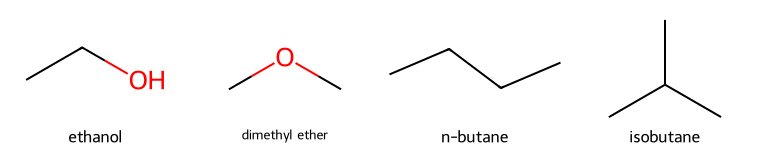

In [8]:
# Constitutional isomers: identical formula, different graphs (seen in the degree sequence).
pairs = [("ethanol", "CCO"), ("dimethyl ether", "COC"),
         ("n-butane", "CCCC"), ("isobutane", "CC(C)C")]
rows, mols = [], []
for name, smi in pairs:
    m = Chem.MolFromSmiles(smi); mols.append(m)
    A = Chem.GetAdjacencyMatrix(m)
    rows.append((name, rdMolDescriptors.CalcMolFormula(m), str(sorted(A.sum(1).tolist())),
                 Chem.MolToSmiles(m)))
print(pd.DataFrame(rows, columns=["name", "formula", "degree sequence", "canonical SMILES"]).to_string(index=False))
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(190, 150), legends=[p[0] for p in pairs])

<p class="caption"><b>Figure 4.</b> Two pairs of constitutional isomers. Each pair shares a molecular formula (C₂H₆O; C₄H₁₀) but is a different graph. For butane the graphs are even distinguishable by a cheap invariant — n-butane's degree sequence is [1,1,2,2] (a chain) while isobutane's is [1,1,1,3] (a central branch), as the table prints. Ethanol and dimethyl ether share the degree sequence [1,1,2]; the graphs still differ because the degree-2 node is <em>oxygen</em> in one and <em>carbon</em> in the other — a reminder that these are <strong>labelled</strong> graphs and the labels are part of the identity. Comparing two molecules therefore means comparing labelled graphs, which is why a string like SMILES must be canonicalised before two records can be matched<sup class="c"><a href="#r8">[8]</a></sup>.</p>

<div class="box bridge"><h4>Chemistry box — "formula" vs "structure" vs "identity"</h4>
<p>Three increasingly strict notions of sameness. Two molecules with the same <strong>formula</strong> share atom counts. Two with the same <strong>constitution</strong> (graph) share atom counts <em>and</em> connectivity. Two that are truly the <strong>same compound</strong> share constitution <em>and</em> 3-D configuration. Databases key molecules on the strictest practical level with a hash of the graph (and optionally stereochemistry) called the InChIKey<sup class="c"><a href="#r17">[17]</a></sup> — Unit 3's subject. When you deduplicate a dataset, you are choosing which of these three notions to deduplicate on, and the choice changes your results.</p></div>

How fast does the number of constitutional isomers grow? Already for the small saturated formula C₆H₁₄ there are exactly five, and the count rises steeply with size — part of why chemical space is astronomically large (Unit 8). The cell lists the five hexane isomers and their degree sequences, which also exposes a subtlety: the degree sequence is a *necessary* but not a *sufficient* invariant for telling graphs apart.

In [9]:
# The five constitutional isomers of C6H14, by degree sequence.
hexanes = {"n-hexane": "CCCCCC", "2-methylpentane": "CCCC(C)C", "3-methylpentane": "CCC(C)CC",
           "2,2-dimethylbutane": "CCC(C)(C)C", "2,3-dimethylbutane": "CC(C)C(C)C"}
rows = []
for name, smi in hexanes.items():
    m = Chem.MolFromSmiles(smi)
    rows.append((name, rdMolDescriptors.CalcMolFormula(m), str(sorted(Chem.GetAdjacencyMatrix(m).sum(1).tolist()))))
df = pd.DataFrame(rows, columns=["isomer", "formula", "degree sequence"])
print(df.to_string(index=False))
print("\nall five share formula C6H14; 2-methyl- and 3-methylpentane even share a degree sequence")

            isomer formula    degree sequence
          n-hexane   C6H14 [1, 1, 2, 2, 2, 2]
   2-methylpentane   C6H14 [1, 1, 1, 2, 2, 3]
   3-methylpentane   C6H14 [1, 1, 1, 2, 2, 3]
2,2-dimethylbutane   C6H14 [1, 1, 1, 1, 2, 4]
2,3-dimethylbutane   C6H14 [1, 1, 1, 1, 3, 3]

all five share formula C6H14; 2-methyl- and 3-methylpentane even share a degree sequence


All five are C₆H₁₄, yet they are five different compounds with different boiling points. Notice that 2-methylpentane and 3-methylpentane share the degree sequence [1,1,1,2,2,3] but are still different molecules (the branch sits at a different position) — so a matching degree sequence does *not* prove two graphs are the same. This is the chemical face of the graph-isomorphism problem: cheap invariants can quickly prove two molecules **different** (if any invariant differs) but cannot by themselves prove them **identical**; that requires a canonical form (Unit 3).

## 4. The three C's: constitution, configuration, conformation

Chemists organise structural description into a strict hierarchy — three levels, each adding information the previous one lacked. Computer scientists meet this hierarchy as "which parts of the structure are discrete graph facts, and which are continuous geometry". Getting the three straight removes most confusion about what a cheminformatics object does and does not know<sup class="c"><a href="#r1">[1]</a></sup>.

1. **Constitution** — *which atoms are bonded to which*. This is the labelled graph of §1–§3, and nothing more. Changing constitution means changing an edge; it gives a different compound (a constitutional isomer). Breaking or making a bond is a chemical reaction.
2. **Configuration** — *the fixed 3-D arrangement at points where the graph alone is ambiguous*, namely chiral centres and double bonds. Two molecules with the same constitution but different configuration are stereoisomers; interconverting them requires **breaking a bond** (so they are stable, separable substances). This is §5–§9.
3. **Conformation** — *the shapes a single molecule takes by rotating around its single bonds*, with no bond broken. One molecule has infinitely many conformations, interconverting freely at room temperature. This is §10.

The crucial asymmetry for a programmer: constitution and configuration are **discrete** facts that live naturally in the graph (an edge; a stereo-flag on a node or edge), whereas conformation is **continuous** geometry that the 2-D graph does not store at all. The cell below states the hierarchy as a small reference table with one molecular example per level.

In [10]:
# The three-level hierarchy of molecular description, with an example and what interconverts the pair.
hier = pd.DataFrame([
    ("constitution", "which atoms bond to which (the graph)", "ethanol vs dimethyl ether",
     "make/break a bond (a reaction)", "discrete (edges)"),
    ("configuration", "fixed 3-D layout at chiral centres / double bonds", "(R)- vs (S)-ibuprofen",
     "break a bond (not spontaneous)", "discrete (stereo flags)"),
    ("conformation", "shape from rotating single bonds", "anti vs gauche butane",
     "rotate a single bond (free, fast)", "continuous (coordinates)"),
], columns=["level", "what it specifies", "example pair", "what it takes to interconvert", "data type"])
print(hier.to_string(index=False))

        level                                 what it specifies              example pair     what it takes to interconvert                data type
 constitution             which atoms bond to which (the graph) ethanol vs dimethyl ether    make/break a bond (a reaction)         discrete (edges)
configuration fixed 3-D layout at chiral centres / double bonds     (R)- vs (S)-ibuprofen    break a bond (not spontaneous)  discrete (stereo flags)
 conformation                  shape from rotating single bonds     anti vs gauche butane rotate a single bond (free, fast) continuous (coordinates)


Read the last two columns together: the effort to interconvert a pair tells you which level separates them, and that in turn tells you whether the distinction lives in the graph or only in 3-D coordinates. A fingerprint computed from the 2-D graph (Unit 5) captures constitution fully, captures configuration only if we explicitly include stereo flags, and captures conformation not at all. That is not a bug — it is the correct behaviour for a 2-D representation — but it is a fact you must hold when you choose a representation for a model.

## 5. Chirality and enantiomers — when the graph is not enough

**Chirality** (from the Greek for "hand") is the property of a shape that is not superimposable on its mirror image — like your left and right hands, which have the same parts connected the same way yet cannot be laid on top of each other. In molecules, chirality most often comes from a **stereocentre**: a carbon atom bonded to four *different* groups. Swap any two of those groups and you get the mirror image, a distinct molecule called an **enantiomer**. The two enantiomers have identical constitution — the same graph, the same bonds, the same formula — and differ only in the handedness of the 3-D arrangement<sup class="c"><a href="#r11">[11]</a></sup>.

<div class="box bridge"><h4>Chemistry box — stereocentre, enantiomer, diastereomer, racemate</h4>
<p>A <strong>stereocentre</strong> (chiral centre) is an atom whose swap of two neighbours gives a different stereoisomer — classically a carbon with four different substituents. Two stereoisomers that are mirror images of each other are <strong>enantiomers</strong>; stereoisomers that are <em>not</em> mirror images (they differ at some but not all stereocentres) are <strong>diastereomers</strong>. A 50:50 mixture of two enantiomers is a <strong>racemate</strong> (or racemic mixture) and is often what a non-selective synthesis produces. Enantiomers have identical physical properties (melting point, solubility) in an ordinary, non-chiral environment — but a living body is intensely chiral, so it can tell them apart.</p></div>

The cell finds caffeine's stereocentres (it has none — it is achiral) and contrasts it with ibuprofen, whose single stereocentre makes it chiral.

caffeine    C8H10N4O2  stereocentres: []
ibuprofen   C13H18O2   stereocentres: [(8, '?')]


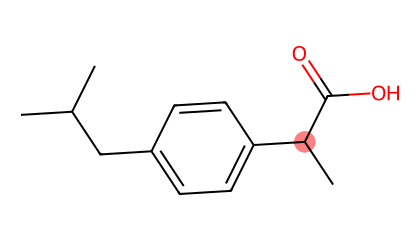

In [11]:
# Detect stereocentres. Caffeine (achiral) vs ibuprofen (one stereocentre -> chiral).
def centres(name, smi):
    m = Chem.MolFromSmiles(smi)
    cc = Chem.FindMolChiralCenters(m, useLegacyImplementation=False, includeUnassigned=True)
    print(f"{name:11s} {rdMolDescriptors.CalcMolFormula(m):10s} stereocentres: {cc}")
    return m
m_caf = centres("caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C")
m_ibu = centres("ibuprofen", "CC(C)Cc1ccc(C(C)C(=O)O)cc1")
# Highlight ibuprofen's stereocentre atom in the drawing.
ctr = [i for i, _ in Chem.FindMolChiralCenters(m_ibu, useLegacyImplementation=False, includeUnassigned=True)]
Draw.MolToImage(m_ibu, size=(420, 240), highlightAtoms=ctr)

<p class="caption"><b>Figure 5.</b> Ibuprofen with its single stereocentre highlighted — the carbon bearing the methyl group next to the acid, bonded to four different groups (H, CH₃, the aromatic ring system, and the carboxylic-acid carbon). Caffeine, by contrast, has no stereocentre at all, so it is <em>achiral</em> and has a single form. The marker <code>'?'</code> in the printout means the centre's handedness is <em>unspecified</em> in the SMILES we gave — the string described the constitution but left the configuration open, which is itself a common and dangerous ambiguity in real data.</p>

<div class="box warn"><h4>A SMILES without stereo flags is an incomplete description</h4>
<p>The ibuprofen SMILES above has a real stereocentre but no handedness marked, so it denotes <em>either</em> enantiomer — a set of two molecules, not one. Marketed ibuprofen is in fact sold as the racemate, but many chiral drugs are not, and computing properties or a fingerprint on a stereo-unspecified structure quietly averages over physically distinct molecules. "Does my dataset specify stereochemistry, and consistently?" is one of the first questions Unit 7 (data curation) forces you to ask.</p></div>

## 6. R/S handedness and the Cahn–Ingold–Prelog rules — traced by hand

Naming which enantiomer you mean requires an unambiguous label for handedness. The universal scheme is **R/S**, defined by the Cahn–Ingold–Prelog (CIP) rules<sup class="c"><a href="#r9">[9]</a></sup>, later refined<sup class="c"><a href="#r10">[10]</a></sup>. The procedure at a stereocentre is a small, deterministic algorithm — exactly the kind of thing a computer scientist appreciates:

1. **Rank the four substituents by priority.** Higher atomic number wins. If two substituents tie at the first atom, move outward and compare the sets of atoms attached to them, highest-first, until the tie breaks. (Double bonds are handled by adding "duplicate" phantom atoms.)
2. **Orient** the molecule so the lowest-priority group points away from you.
3. **Read** the remaining three, highest to lowest. Clockwise is **R** (Latin *rectus*, right); counter-clockwise is **S** (*sinister*, left).

Let us trace it by hand for the stereocentre of **alanine**, the simplest chiral amino acid, whose centre carbon is bonded to four groups: an amino group –NH₂, a carboxylic acid –COOH, a methyl –CH₃, and a hydrogen –H.

**Step 1 — rank by first atom.** The four first atoms are N (of NH₂), C (of COOH), C (of CH₃) and H. By atomic number, N (7) beats the two carbons (6), which beat H (1). So the amino group is priority **1** and hydrogen is priority **4**; the two carbons are tied and need step 1b.

**Step 1b — break the C–C tie one shell out.** Look at what each tied carbon is itself bonded to (excluding the centre), as a set ranked highest-first:

<div class="eq">
COOH carbon → {O, O, O}  (the C=O counts its oxygen twice as a duplicate, plus the –OH oxygen)<br>
CH₃ carbon  → {H, H, H}
</div>

Comparing the two sets highest-first, O (8) beats H (1) immediately, so the **COOH carbon is priority 2** and the **CH₃ carbon is priority 3**.

**Step 2–3 — assign.** Final ranking: NH₂ (1) > COOH (2) > CH₃ (3) > H (4). For the naturally occurring L-alanine, orienting the H (priority 4) away and reading 1→2→3 traces **counter-clockwise**, giving the label **S**. The cell confirms this with RDKit's CIP labeller — the same algorithm, automated.

L-alanine (natural)  -> CIP [(1, 'S')]
D-alanine (mirror)   -> CIP [(1, 'R')]


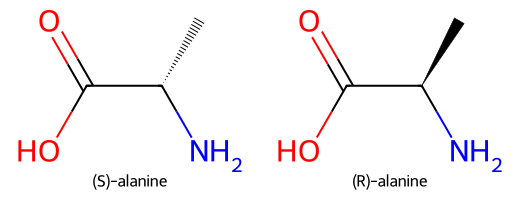

In [12]:
# Confirm the hand-traced CIP assignment for L-alanine (expected S) and its mirror image (R).
for label, smi in [("L-alanine (natural)", "C[C@@H](C(=O)O)N"),
                   ("D-alanine (mirror)",  "C[C@H](C(=O)O)N")]:
    m = Chem.MolFromSmiles(smi)
    rdCIPLabeler.AssignCIPLabels(m)
    codes = [(a.GetIdx(), a.GetProp("_CIPCode")) for a in m.GetAtoms() if a.HasProp("_CIPCode")]
    print(f"{label:20s} -> CIP {codes}")
# Draw the enantiomeric pair as wedge/dash structures.
mols = [Chem.MolFromSmiles(s) for s in ["C[C@@H](C(=O)O)N", "C[C@H](C(=O)O)N"]]
for m in mols: Chem.rdDepictor.Compute2DCoords(m)
Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(260, 200), legends=["(S)-alanine", "(R)-alanine"])

<p class="caption"><b>Figure 6.</b> The two enantiomers of alanine, drawn with the wedge (toward you) and dash (away) notation that encodes 3-D handedness on a 2-D page. RDKit's CIP labeller returns <b>S</b> for the natural form and <b>R</b> for its mirror image, exactly matching the by-hand trace above. The two structures are the same graph — identical atoms and bonds — differing only in the handedness at one carbon; no rotation of the molecule can turn one into the other, which is what "non-superimposable mirror images" means.</p>

<div class="box bridge"><h4>Chemistry box — wedges and dashes</h4>
<p>On paper, 3-D handedness is drawn with bond decorations: a solid <strong>wedge</strong> means the bond comes toward the viewer, a hashed <strong>dash</strong> means it goes behind the page, and plain lines lie in the plane. These are the 2-D drawing's only way to record configuration; a flat structure with no wedges/dashes has left its stereocentres unspecified — the ambiguity the previous warning box flagged.</p></div>

## 7. Why handedness can be a matter of life and death: thalidomide

Enantiomers are identical in an ordinary test tube, so why spend a whole algorithm distinguishing them? Because the human body is built almost entirely from single-handed molecules — our amino acids are all L, our sugars all D — so every drug target is a chiral pocket that can bind one enantiomer tightly and the other poorly or differently. The same handedness that your eye can barely see is, to a protein, the difference between a key that fits and one that does not<sup class="c"><a href="#r11">[11]</a></sup>.

The cautionary tale is **thalidomide**, marketed in the late 1950s as a sedative and anti-nausea drug for pregnant women. It was sold as a racemate. The (R)-enantiomer has the intended sedative effect; the (S)-enantiomer is **teratogenic** — it disrupts fetal development — and the drug caused thousands of severe birth defects before it was withdrawn<sup class="c"><a href="#r13">[13]</a></sup>. The structural basis is now understood: the (S)-form binds a protein called cereblon in a way that derails the normal degradation of developmental proteins, and a crystal structure shows each enantiomer sitting differently in the binding site<sup class="c"><a href="#r12">[12]</a></sup>. The cell shows thalidomide's single stereocentre and its two enantiomers.

thalidomide formula: C13H10N2O4 | stereocentres: [(4, '?')]
  enantiomer CIP: S SMILES: O=C1CC[C@H](N2C(=O)c3ccccc3C2=O)C(=O)N1
  enantiomer CIP: R SMILES: O=C1CC[C@@H](N2C(=O)c3ccccc3C2=O)C(=O)N1


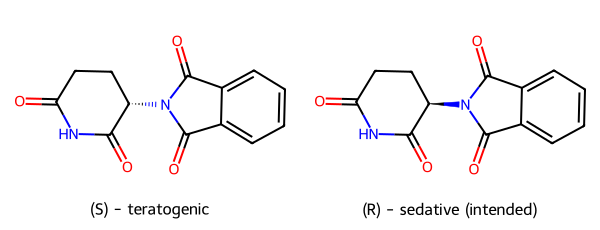

In [13]:
# Thalidomide: one stereocentre, two enantiomers with opposite biological consequences.
thal = Chem.MolFromSmiles("O=C1CCC(N2C(=O)c3ccccc3C2=O)C(=O)N1")
cc = Chem.FindMolChiralCenters(thal, useLegacyImplementation=False, includeUnassigned=True)
print("thalidomide formula:", rdMolDescriptors.CalcMolFormula(thal), "| stereocentres:", cc)
enants = list(EnumerateStereoisomers(thal))
effect = {"R": "(R) - sedative (intended)", "S": "(S) - teratogenic"}
legs = []
for e in enants:
    rdCIPLabeler.AssignCIPLabels(e)
    code = next(a.GetProp("_CIPCode") for a in e.GetAtoms() if a.HasProp("_CIPCode"))
    legs.append(effect[code])                      # legend derived from each molecule's actual CIP code
    print("  enantiomer CIP:", code, "SMILES:", Chem.MolToSmiles(e))
Draw.MolsToGridImage(enants, molsPerRow=2, subImgSize=(300, 230), legends=legs)

<p class="caption"><b>Figure 7.</b> The two enantiomers of thalidomide. RDKit enumerates exactly two (one stereocentre → 2¹ = 2 forms) and assigns them R and S. They are the same graph; the only difference is the handedness at the ring carbon bearing the phthalimide nitrogen. The (R) form carries the therapeutic activity and the (S) form the teratogenic activity — a difference invisible to the molecular formula and to a stereo-blind fingerprint, yet decisive in a human body.</p>

<div class="box warn"><h4>Why selling only the "good" enantiomer would not have helped here</h4>
<p>A tempting lesson is "always use the single safe enantiomer". For thalidomide specifically that would not have worked: the two enantiomers <em>interconvert</em> in the body (they racemise under physiological conditions), so a pure (R) dose would partly convert to (S) regardless<sup class="c"><a href="#r13">[13]</a></sup>. The real lessons are broader and they are cheminformatics lessons: (i) stereochemistry is part of a molecule's identity and must be tracked as data, not dropped; and (ii) two records that look identical to a stereo-blind pipeline can be pharmacologically opposite. The modern importance of chirality in drug design<sup class="c"><a href="#r11">[11]</a></sup> is why regulators now expect each enantiomer to be characterised separately.</p></div>

## 8. Enumerating stereoisomers — and why the count explodes

A molecule with $n$ independent stereocentres has up to $2^n$ stereoisomers, because each centre is an independent binary choice (R or S). RDKit's `EnumerateStereoisomers` generates them for you — invaluable when a database record leaves stereochemistry unspecified and you must consider every possibility. We apply it to **ephedrine**, a decongestant with two stereocentres, and to the open-chain form of the sugar **ribose**, with three.

ephedrine  stereocentres=2  2^n= 4  enumerated=4
ribose     stereocentres=3  2^n= 8  enumerated=8


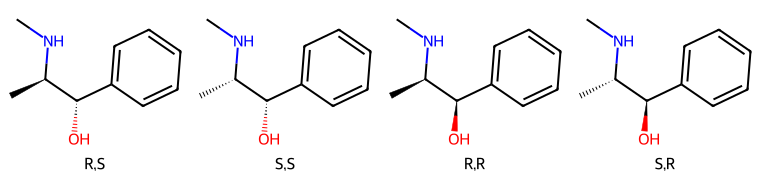

In [14]:
# Enumerate all stereoisomers; count grows as 2^(number of stereocentres).
def enumerate_stereo(name, smi):
    m = Chem.MolFromSmiles(smi)
    ncentre = len(Chem.FindMolChiralCenters(m, useLegacyImplementation=False, includeUnassigned=True))
    isos = list(EnumerateStereoisomers(m))
    print(f"{name:10s} stereocentres={ncentre}  2^n={2**ncentre:>2d}  enumerated={len(isos)}")
    return m, isos
m_eph, eph_isos = enumerate_stereo("ephedrine", "CC(C(c1ccccc1)O)NC")
m_rib, rib_isos = enumerate_stereo("ribose",    "OCC(O)C(O)C(O)C=O")
# Label the four ephedrine stereoisomers by their (centre-1, centre-2) CIP codes.
legs = []
for it in eph_isos:
    rdCIPLabeler.AssignCIPLabels(it)
    legs.append(",".join(a.GetProp("_CIPCode") for a in it.GetAtoms() if a.HasProp("_CIPCode")))
Draw.MolsToGridImage(eph_isos, molsPerRow=4, subImgSize=(190, 180), legends=legs)

<p class="caption"><b>Figure 8.</b> The four stereoisomers of ephedrine (2 stereocentres → 2² = 4), each labelled by its pair of CIP codes. The (1R,2S)/(1S,2R) pair are the two enantiomers of <em>ephedrine</em> proper; the (1S,2S)/(1R,2R) pair are <em>pseudoephedrine</em>. Ephedrine and pseudoephedrine are <strong>diastereomers</strong> — same graph, differing at one of the two centres — and they are genuinely different drugs with different potencies and uses, a concrete illustration that a single constitution can hide several distinct medicines. Ribose's three centres give 2³ = 8 isomers, as the printout confirms.</p>

<div class="box bridge"><h4>Chemistry box — the 2ⁿ rule and its exceptions</h4>
<p>The "up to 2ⁿ" wording matters. Symmetry can make some of the 2ⁿ combinations identical (so-called <em>meso</em> compounds have an internal mirror plane and thus fewer distinct isomers), and double bonds add their own two-way (E/Z) choices on top of the chiral centres. RDKit's enumerator accounts for the chiral and double-bond centres it detects; the exact count for a real molecule is a property of its graph symmetry, not simply 2 raised to a power.</p></div>

The clearest example of the exception is **tartaric acid**, which has two stereocentres — so the naive count is 2² = 4 — yet only *three* distinct stereoisomers exist. The cell enumerates them and shows why.

stereocentres=2  naive 2^n=4  distinct stereoisomers=3


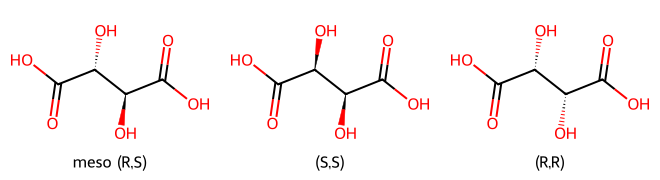

In [15]:
# Tartaric acid: 2 stereocentres but only 3 distinct stereoisomers (one is a meso compound).
tar = Chem.MolFromSmiles("OC(=O)C(O)C(O)C(=O)O")
nc = len(Chem.FindMolChiralCenters(tar, useLegacyImplementation=False, includeUnassigned=True))
isos = list(EnumerateStereoisomers(tar))
print(f"stereocentres={nc}  naive 2^n={2**nc}  distinct stereoisomers={len(isos)}")
legs = []
for it in isos:
    rdCIPLabeler.AssignCIPLabels(it)
    labs = [a.GetProp("_CIPCode") for a in it.GetAtoms() if a.HasProp("_CIPCode")]
    tag = "meso (R,S)" if labs == ["R", "S"] or labs == ["S", "R"] else f"({labs[0]},{labs[1]})"
    legs.append(tag)
Draw.MolsToGridImage(isos, molsPerRow=3, subImgSize=(220, 180), legends=legs)

<p class="caption"><b>Figure 9.</b> The three stereoisomers of tartaric acid, not four. The (R,R) and (S,S) forms are a pair of enantiomers; the (R,S) form is its own mirror image — an internal mirror plane makes the two halves cancel — so it is <em>achiral</em> despite having two stereocentres. This "meso" form is a single compound, which is why the distinct count is 3, not 2² = 4. The exact number of stereoisomers is a property of the molecule's graph symmetry, exactly as the box above warns; never hard-code 2ⁿ.</p>

## 9. Double bonds: cis/trans and E/Z

Stereoisomerism is not confined to chiral centres. A carbon–carbon double bond cannot rotate (that is what makes it a double bond), so the groups on its two ends are locked into one of two arrangements. When the two higher-priority groups sit on the *same* side the bond is **Z** (German *zusammen*, together; loosely "cis"); on *opposite* sides it is **E** (*entgegen*, opposite; loosely "trans"). Priorities are assigned by the same CIP rules as R/S<sup class="c"><a href="#r10">[10]</a></sup>. The cis and trans forms are distinct, separable, non-interconverting compounds — configuration, not conformation. The cell enumerates the two forms of 2-butene from a double bond left unspecified.

trans (E)  C/C=C/C
cis (Z)    C/C=C\C


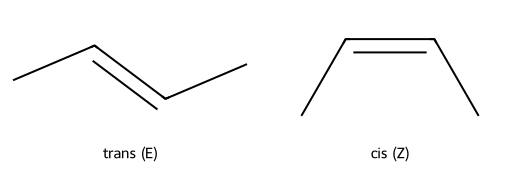

In [16]:
# A double bond with unspecified geometry has two configurations: E and Z.
but = Chem.MolFromSmiles("CC=CC")            # 2-butene, geometry unspecified
forms = list(EnumerateStereoisomers(but))
labelled = []
for f in forms:
    s = Chem.MolToSmiles(f)
    tag = "trans (E)" if "/C=C/" in s or "\\C=C\\" in s else "cis (Z)"
    labelled.append((tag, s)); print(f"{tag:10s} {s}")
mols = [Chem.MolFromSmiles(s) for _, s in labelled]
Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(260, 170), legends=[t for t, _ in labelled])

<p class="caption"><b>Figure 10.</b> The two configurations of 2-butene. In the cis (Z) form the two methyl groups are on the same side of the double bond; in the trans (E) form they are opposite. These are different substances with different boiling points and shapes, generated here from a single stereo-unspecified SMILES — once again, the flat connectivity underdetermines the molecule, and the geometry must be stored explicitly. Double-bond geometry is pharmacologically real: the visual pigment retinal works by flipping between a cis and a trans form when it absorbs light.</p>

## 10. Two near-isomers that trip up pipelines: tautomers and resonance

Two further phenomena look like isomerism and routinely confuse both students and software, so we pin them down precisely with the graph vocabulary.

- **Tautomers** are constitutional isomers that interconvert rapidly by moving a hydrogen atom and shifting a double bond — most commonly the **keto–enol** pair. They are *genuinely different graphs* (a bond and an H have moved) that exist in a fast equilibrium, so a single compound in solution is really a mixture of tautomers. This is a nightmare for database identity: the "same" molecule may be drawn as any of its tautomers, and a stereo- or tautomer-blind lookup will miss matches<sup class="c"><a href="#r14">[14]</a></sup>. Large databases contain millions of molecules whose stored tautomer is partly a matter of chance<sup class="c"><a href="#r15">[15]</a></sup>, which is why Unit 4 devotes effort to choosing one canonical tautomer.
- **Resonance** is the opposite situation: *one* molecule, *one* graph, that a single Kekulé-style drawing cannot capture because its electrons are delocalised. The carboxylate ion and benzene are the classic cases — the "two drawings" are not two molecules but two incomplete pictures of one, the quantum-mechanical description of which is Pauling's<sup class="c"><a href="#r16">[16]</a></sup>. RDKit stores resonance-delocalised bonds as a single aromatic or averaged form, which is why the carboxylate's two C–O bonds come out equal.

The cell shows both: it enumerates the tautomers of a keto–enol system and draws a resonance case where the two "drawings" are one molecule.

acetylacetone (keto/enol)  tautomers found: 5  | canonical: CC(=O)CC(C)=O
2-pyridone                 tautomers found: 3  | canonical: O=c1cccc[nH]1
acetate C-O bond types as drawn: ['DOUBLE', 'SINGLE'] (the two are chemically equivalent by resonance)


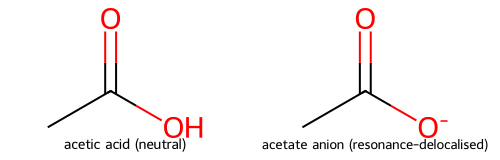

In [17]:
# Tautomers are different graphs in equilibrium; resonance is one graph, delocalised.
enum = rdMolStandardize.TautomerEnumerator()
for name, smi in [("acetylacetone (keto/enol)", "CC(=O)CC(C)=O"), ("2-pyridone", "O=c1cccc[nH]1")]:
    m = Chem.MolFromSmiles(smi)
    taut = enum.Enumerate(m)
    print(f"{name:26s} tautomers found: {len(taut)}  | canonical: {Chem.MolToSmiles(enum.Canonicalize(m))}")
# Resonance: the acetate anion's two C-O bonds are equivalent (delocalised), not one single + one double.
ac = Chem.MolFromSmiles("CC(=O)[O-]")
co_bonds = [str(b.GetBondType()) for b in ac.GetBonds() if {b.GetBeginAtom().GetSymbol(), b.GetEndAtom().GetSymbol()} == {"C", "O"}]
print("acetate C-O bond types as drawn:", co_bonds, "(the two are chemically equivalent by resonance)")
Draw.MolsToGridImage([Chem.MolFromSmiles("CC(=O)O"), Chem.MolFromSmiles("CC(=O)[O-]")],
                     molsPerRow=2, subImgSize=(250, 160), legends=["acetic acid (neutral)", "acetate anion (resonance-delocalised)"])

<p class="caption"><b>Figure 11.</b> Left/right: acetic acid and its acetate anion. In the anion the negative charge is shared equally over both oxygens (resonance) — the two C–O bonds are physically identical even though a single line-drawing is forced to draw one as double and one as single, which is why the printed bond types look asymmetric while the real molecule is symmetric. The accompanying printout shows acetylacetone and 2-pyridone each have several tautomers in RDKit's enumeration: these are different graphs in rapid equilibrium, the opposite situation to resonance. Keeping the two ideas apart — <em>many graphs, one compound</em> (resonance) versus <em>many graphs, an equilibrium of compounds</em> (tautomers) — prevents a large class of data-curation errors.</p>

## 11. One graph, many shapes: 2-D topology versus 3-D geometry

We reach the third level of the hierarchy. The molecular graph — constitution plus configuration — still does not fix the molecule's actual shape in space, because single bonds rotate freely. Each distinct shape a molecule adopts by such rotation is a **conformation** (or **conformer**), and a flexible molecule has many, all interconverting billions of times a second at body temperature. The 2-D structure you draw is a *topological* object; the 3-D shape is *geometry*, and generating plausible geometries from the graph is a whole sub-field<sup class="c"><a href="#r18">[18]</a></sup>.

<div class="box bridge"><h4>Chemistry box — conformation vs configuration, one more time</h4>
<p>The pair that students most often confuse. <strong>Configuration</strong> (R/S, E/Z) cannot change without breaking a bond — the forms are separate bottled compounds. <strong>Conformation</strong> changes by mere rotation about single bonds — the forms are the same compound caught in different poses, and you cannot bottle one separately. Butane's "anti" and "gauche" forms are conformations of one substance; (R)- and (S)-ibuprofen are configurations of two.</p></div>

We make conformers concrete on the smallest flexible molecule, **n-butane**, whose single rotatable C–C bond gives a one-dimensional landscape of shapes. The cell embeds several 3-D conformers and reads off the central dihedral angle that distinguishes them. <em>This is the only mildly heavy step in the unit; it stays well under a second because the molecule is tiny and we ask for only a handful of conformers.</em>

In [18]:
# Generate a few 3-D conformers of n-butane and read the central C-C-C-C dihedral angle.
but = Chem.AddHs(Chem.MolFromSmiles("CCCC"))                     # explicit H needed for 3-D geometry
ids = AllChem.EmbedMultipleConfs(but, numConfs=8, randomSeed=0xf00d)   # ETKDG distance-geometry embedding
AllChem.MMFFOptimizeMoleculeConfs(but)                          # relax each to a local energy minimum
dihedrals = [rdMolTransforms.GetDihedralDeg(but.GetConformer(i), 0, 1, 2, 3) for i in ids]
print("number of conformers:", len(ids))
print("central C-C-C-C dihedral per conformer (deg):", [round(d) for d in dihedrals])
print("clustered near +-180 = 'anti' (extended); near +-60 = 'gauche' (bent)")

number of conformers: 8
central C-C-C-C dihedral per conformer (deg): [-180, -180, 65, -65, 180, 65, -65, -65]
clustered near +-180 = 'anti' (extended); near +-60 = 'gauche' (bent)


The eight conformers do not scatter at random: their central dihedral clusters near ±180° (the extended **anti** form) and near ±60° (the bent **gauche** forms). These are butane's energy minima — the shapes it actually spends time in — and they are the same molecule, not isomers. The cell below quantifies how different the shapes are with a pairwise root-mean-square deviation (RMSD) of atomic positions and plots the dihedral landscape.

largest pairwise RMSD between two conformers: 1.22 A


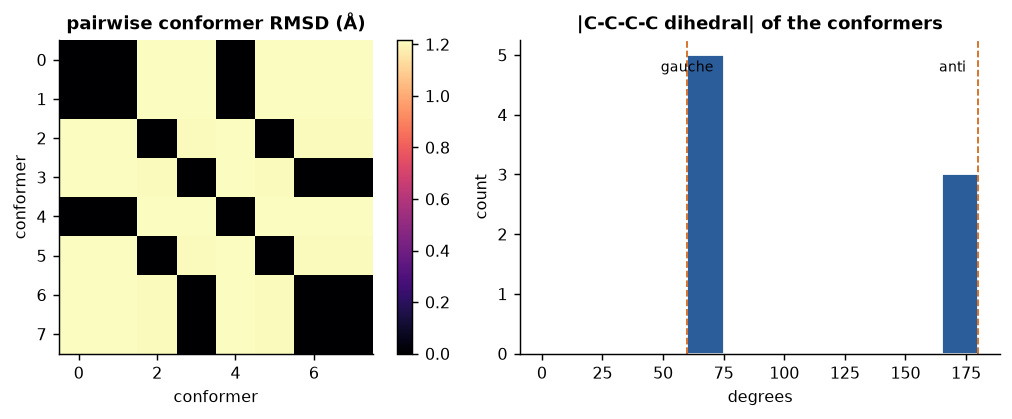

In [19]:
# How different are the shapes? Pairwise heavy-atom RMSD, and the dihedral distribution.
nconf = len(ids)
rms = np.zeros((nconf, nconf))
for i in range(nconf):
    for j in range(nconf):
        rms[i, j] = rdMolAlign.GetBestRMS(but, but, i, j)        # best-fit RMSD between conformers i and j
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
im = ax1.imshow(rms, cmap="magma"); ax1.set_title("pairwise conformer RMSD (Å)")
ax1.set_xlabel("conformer"); ax1.set_ylabel("conformer"); fig.colorbar(im, ax=ax1, fraction=0.046)
ax2.hist(np.abs(dihedrals), bins=np.arange(0, 181, 15), color="#2b5d9b", edgecolor="w")
ax2.axvline(60, color="#d2691e", ls="--", lw=1); ax2.axvline(180, color="#d2691e", ls="--", lw=1)
ax2.set_title("|C-C-C-C dihedral| of the conformers"); ax2.set_xlabel("degrees"); ax2.set_ylabel("count")
ax2.text(60, ax2.get_ylim()[1]*0.9, "gauche", ha="center", fontsize=8)
ax2.text(175, ax2.get_ylim()[1]*0.9, "anti", ha="right", fontsize=8)
print("largest pairwise RMSD between two conformers: %.2f A" % rms.max())
fig.tight_layout()

<p class="caption"><b>Figure 12.</b> Left: the pairwise RMSD between butane's eight conformers; off-diagonal values up to about 1.2 Å show that the "same molecule" occupies measurably different shapes. Right: the conformers' central dihedral angles pile up at the gauche (~60°) and anti (~180°) minima marked by the dashed lines — exactly the textbook rotational profile of butane, recovered here from a distance-geometry embedding. For a drug-sized molecule this landscape has many dimensions; which conformer binds a protein is a central question of the <em>structure-based</em> methods that belong to the bioinformatics course, not here.</p>

<div class="box bridge"><h4>Bridge — where 3-D goes from here, and where it does not</h4>
<p>This unit stops at generating conformers of a single small molecule, which is cheap. Everything downstream of that — docking a conformer into a protein, scoring binding, molecular dynamics — is <strong>structure-based</strong> and deliberately out of scope for this ligand-only course (it is covered in the companion bioinformatics course). We return to the small-molecule side of 3-D in Unit 16 (3-D descriptors and shape). The practical reason 2-D methods dominate cheminformatics is that they are fast, deterministic and need no conformer at all — but they pay for it by being blind to shape, and the flatness of a dataset's molecules is itself a quantity worth watching<sup class="c"><a href="#r19">[19]</a></sup><sup class="c"><a href="#r20">[20]</a></sup>.</p></div>

The conformers are not equally likely: the extended anti form is lower in energy than the bent gauche forms, so a molecule spends more time anti. We can quantify this with the same force field that relaxed the geometries — a classical approximation of molecular energy that is cheap to evaluate (and is as far toward physics as this ligand-only course goes).

In [20]:
# Relative energies of the conformers: anti (extended) sits below gauche (bent).
props = AllChem.MMFFGetMoleculeProperties(but)
energy, dih = [], []
for i in ids:
    ff = AllChem.MMFFGetMoleculeForceField(but, props, confId=i)
    energy.append(ff.CalcEnergy())
    dih.append(abs(rdMolTransforms.GetDihedralDeg(but.GetConformer(i), 0, 1, 2, 3)))
rel = np.array(energy) - min(energy)
tab = pd.DataFrame({"|dihedral|": np.round(dih).astype(int), "rel_energy_kcal": np.round(rel, 2)})
tab["form"] = np.where(tab["|dihedral|"] > 120, "anti", "gauche")
print(tab.sort_values("|dihedral|").to_string(index=False))
print("\nmean anti energy: %.2f   mean gauche energy: %.2f  (kcal/mol, relative)"
      % (rel[np.array(dih) > 120].mean(), rel[np.array(dih) <= 120].mean()))

 |dihedral|  rel_energy_kcal   form
         65             0.78 gauche
         65             0.78 gauche
         65             0.78 gauche
         65             0.78 gauche
         65             0.78 gauche
        180             0.00   anti
        180             0.00   anti
        180             0.00   anti

mean anti energy: 0.00   mean gauche energy: 0.78  (kcal/mol, relative)


The anti conformers come out at the energy minimum (relative energy 0) while the gauche conformers sit roughly 0.8 kcal/mol higher, reproducing the textbook rotational profile of butane from nothing but the graph and a force field. This is the entire logic of conformer generation in one small molecule: enumerate shapes, score them, keep the low-energy ones — and it is why a single molecular graph is best thought of as a *distribution* over 3-D shapes rather than one shape. Where that distribution meets a protein is the structure-based territory of the companion course.

## 12. Why the graph view pays off: a glance ahead to learned representations

Everything in this course is, at bottom, computation on the labelled graph we built in §1–§2. It is worth seeing why that framing is powerful. A **fingerprint** (Unit 5) is a fixed recipe that reads the graph's local neighbourhoods and hashes them into a bit-vector<sup class="c"><a href="#r25">[25]</a></sup>; a **scaffold** (Unit 11) is a subgraph obtained by pruning the graph's side chains<sup class="c"><a href="#r24">[24]</a></sup>; **similarity search** (Unit 11) compares two molecules by comparing their graph-derived vectors<sup class="c"><a href="#r27">[27]</a></sup>; and the public databases you will query in Unit 6 store, index and serve exactly these graphs<sup class="c"><a href="#r28">[28]</a></sup>.

The deepest version of the idea is to stop hand-designing the recipe and let a model *learn* what to read off the graph. A **graph neural network** treats each atom as a node holding a feature vector and repeatedly updates it by "message passing" — each atom mixes in information from its bonded neighbours, so after a few rounds every atom's vector summarises its local environment<sup class="c"><a href="#r21">[21]</a></sup>. This is precisely a learned, trainable generalisation of the fixed fingerprint<sup class="c"><a href="#r22">[22]</a></sup>, and it operates directly on the adjacency structure we built by hand in §2. The molecular graph is, in this sense, not just a storage format but the native input of modern molecular machine learning<sup class="c"><a href="#r6">[6]</a></sup><sup class="c"><a href="#r23">[23]</a></sup> — which is why this unit spent its first half making the graph utterly concrete. We build a minimal message-passing step by hand in Unit 15; you now have the graph it runs on.

## 13. Summary

You should now be able to explain, without notes:

- A molecule as a labelled graph: atoms are nodes with element/charge/aromaticity labels, bonds are edges with order labels; degree, rings (cycles) and connected components in both vocabularies.
- The adjacency matrix: symmetric, zero diagonal, row sums equal degrees; how to build one by hand from an edge list and confirm it in RDKit; the bond-order–weighted variant; and why the atom numbering is arbitrary while the molecule is not.
- Graph invariants (degree sequence, ring count, diameter, Wiener index) and why invariants, not the raw matrix, are what we trust.
- Isomerism: constitutional isomers (different graph, same formula) versus stereoisomers (same graph, different 3-D arrangement).
- The three-level hierarchy constitution → configuration → conformation, what interconverts each pair, and which levels are discrete graph facts versus continuous geometry.
- Chirality, stereocentres, enantiomers, diastereomers and racemates; the R/S CIP procedure traced by hand and confirmed by code; the thalidomide case and the precise reason two enantiomers can act oppositely.
- Enumerating stereoisomers and the up-to-2ⁿ growth; cis/trans (E/Z) double-bond stereochemistry; the difference between tautomers (many graphs in equilibrium) and resonance (one delocalised graph).
- Why one 2-D graph maps to many 3-D conformers, how to generate a few for a small molecule, and where 3-D work hands off to the structure-based (bioinformatics) course.

## 14. Self-assessment

<details><summary>1. In the graph view of a molecule, what are the nodes, the edges, and the labels on each?</summary>Nodes are atoms (labelled with element, formal charge, aromaticity and implicit-hydrogen count); edges are covalent bonds (labelled with bond order: single, double, triple, aromatic). This makes a molecule a <em>labelled, undirected</em> graph.</details>

<details><summary>2. An adjacency matrix is symmetric with a zero diagonal and each row sums to a small integer. Explain each of these three facts chemically.</summary>Symmetric: a bond is undirected (if i bonds j then j bonds i). Zero diagonal: an atom is not bonded to itself. Small row sums: the row sum is the atom's heavy-atom degree, capped by valence (C ≤ 4, O ≤ 2, …), so molecular graphs are sparse and low-degree.</details>

<details><summary>3. You build caffeine's adjacency matrix from one SMILES and a colleague builds it from a different (equivalent) SMILES. The matrices differ. Is one of you wrong?</summary>No. The two matrices describe the same molecule but with different atom numberings; they are related by a permutation of rows and columns. The molecule is the invariant; the matrix depends on an arbitrary node ordering. Making the ordering canonical (Unit 3) is what lets identical molecules get identical matrices.</details>

<details><summary>4. Ethanol (CCO) and dimethyl ether (COC) are both C₂H₆O with degree sequence [1,1,2]. Why are they still different graphs?</summary>Because the graphs are <em>labelled</em>: in ethanol the degree-2 atom is carbon (C–C–O), in dimethyl ether it is oxygen (C–O–C). Graph isomorphism for molecules must respect node labels, so equal degree sequences do not imply the same molecule.</details>

<details><summary>5. Place each pair at the correct level of the constitution/configuration/conformation hierarchy: (a) n-butane vs isobutane; (b) (R)- vs (S)-ibuprofen; (c) anti vs gauche butane.</summary>(a) constitution (different connectivity/graph); (b) configuration (same graph, fixed 3-D handedness, needs a broken bond to interconvert); (c) conformation (same molecule, interconverts by free rotation about a single bond).</details>

<details><summary>6. What makes a carbon atom a stereocentre, and what is the relationship between the two molecules you get by swapping two of its substituents?</summary>A carbon bonded to four <em>different</em> groups is a stereocentre. Swapping two substituents gives its mirror image — an enantiomer: same graph, non-superimposable 3-D handedness.</details>

<details><summary>7. Trace the CIP priorities at the alanine stereocentre (neighbours: NH₂, COOH, CH₃, H) and give the ranking.</summary>Rank by first atom: N (7) &gt; the two C (6) &gt; H (1). Break the C–C tie one shell out: the COOH carbon's neighbour set {O,O,O} beats the CH₃ carbon's {H,H,H}. Final: NH₂ (1) &gt; COOH (2) &gt; CH₃ (3) &gt; H (4). Natural L-alanine is then S.</details>

<details><summary>8. Why did selling only the therapeutic (R)-enantiomer of thalidomide not solve the problem, and what two general cheminformatics lessons does the case teach?</summary>Because thalidomide's enantiomers interconvert (racemise) in the body, so a pure (R) dose partly becomes (S) anyway. Lessons: (i) stereochemistry is part of molecular identity and must be tracked as data; (ii) two records identical to a stereo-blind pipeline can be pharmacologically opposite.</details>

<details><summary>9. A molecule has 3 stereocentres. How many stereoisomers at most, and why "at most"?</summary>At most 2³ = 8 (each centre is an independent R/S choice). "At most" because internal symmetry can make some combinations identical (meso compounds), reducing the count below 2ⁿ.</details>

<details><summary>10. Distinguish tautomers from resonance structures using the graph vocabulary.</summary>Tautomers are <em>different</em> graphs (a hydrogen and a double bond have moved) existing in a fast equilibrium — many graphs, an equilibrium of compounds. Resonance structures are <em>one</em> graph with delocalised electrons that a single line-drawing cannot capture — many drawings, one compound.</details>

<details><summary>11. Butane's eight conformers have pairwise RMSDs up to about 1 Å but are the same compound. Why are they not isomers?</summary>They differ only by rotation about single bonds, which breaks no bonds and interconverts freely at room temperature. Isomerism (constitutional or configurational) requires a different graph or a configuration that needs a bond broken to change; conformers meet neither criterion.</details>

<details><summary>12. A 2-D fingerprint captures constitution fully but conformation not at all. Is that a defect, and what follows for choosing a representation?</summary>It is correct behaviour for a 2-D representation, not a defect — but it means a 2-D model is blind to shape and to 3-D-dependent properties. If a property depends on conformation (e.g. binding geometry), a 2-D representation cannot encode it, and you must either add stereo/3-D features or accept the limitation knowingly.</details>

## Glossary

<dl class="gloss">
<dt>Adjacency matrix</dt><dd>An n×n matrix with a 1 (or bond order) where two atoms are bonded; symmetric with zero diagonal; row sums are node degrees.</dd>
<dt>Chirality</dt><dd>The property of a structure not superimposable on its mirror image (like a hand); most often from a carbon with four different substituents.</dd>
<dt>Configuration</dt><dd>The fixed 3-D arrangement at stereocentres and double bonds; changing it requires breaking a bond. R/S and E/Z label it.</dd>
<dt>Conformation (conformer)</dt><dd>A 3-D shape a molecule adopts by rotating its single bonds; interconverts freely, so conformers are the same compound.</dd>
<dt>Constitution</dt><dd>Which atoms are bonded to which — the labelled graph itself.</dd>
<dt>Constitutional isomer</dt><dd>A molecule with the same formula but different connectivity (a different graph).</dd>
<dt>Diastereomer</dt><dd>A stereoisomer that is not a mirror image of the other (differs at some but not all stereocentres).</dd>
<dt>Enantiomer</dt><dd>One of a pair of stereoisomers that are non-superimposable mirror images.</dd>
<dt>E/Z (cis/trans)</dt><dd>The two configurations of a non-rotating double bond; Z = higher-priority groups on the same side, E = opposite.</dd>
<dt>Graph invariant</dt><dd>A quantity (degree sequence, ring count, Wiener index) unchanged by relabelling the nodes; what we trust instead of the raw matrix.</dd>
<dt>Isomers</dt><dd>Distinct molecules sharing a molecular formula; split into constitutional isomers and stereoisomers.</dd>
<dt>R/S</dt><dd>The Cahn–Ingold–Prelog labels for the handedness at a stereocentre, assigned by substituent priority.</dd>
<dt>Racemate</dt><dd>A 50:50 mixture of two enantiomers.</dd>
<dt>Resonance</dt><dd>Electron delocalisation that a single line-drawing cannot represent; several drawings depict one molecule (e.g. carboxylate, benzene).</dd>
<dt>Stereocentre</dt><dd>An atom (classically a carbon with four different groups) whose swap of two neighbours gives a different stereoisomer.</dd>
<dt>Stereoisomer</dt><dd>A molecule with the same graph as another but a different 3-D arrangement (enantiomer or diastereomer).</dd>
<dt>Tautomer</dt><dd>A constitutional isomer that interconverts rapidly by moving a hydrogen and shifting a double bond (e.g. keto–enol).</dd>
<dt>Wiener index</dt><dd>A topological index equal to the sum of shortest-path distances over all atom pairs.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Revised ed. Springer; 2007. <a href="https://doi.org/10.1007/978-1-4020-6291-9">doi:10.1007/978-1-4020-6291-9</a></li>
<li id="r2">Balaban AT. Applications of graph theory in chemistry. <em>J Chem Inf Comput Sci</em>. 1985;25(3):334–343. <a href="https://doi.org/10.1021/ci00047a033">doi:10.1021/ci00047a033</a></li>
<li id="r3">Randić M. Characterization of molecular branching. <em>J Am Chem Soc</em>. 1975;97(23):6609–6615. <a href="https://doi.org/10.1021/ja00856a001">doi:10.1021/ja00856a001</a></li>
<li id="r4">Wiener H. Structural determination of paraffin boiling points. <em>J Am Chem Soc</em>. 1947;69(1):17–20. <a href="https://doi.org/10.1021/ja01193a005">doi:10.1021/ja01193a005</a></li>
<li id="r5">Morgan HL. The generation of a unique machine description for chemical structures — a technique developed at Chemical Abstracts Service. <em>J Chem Doc</em>. 1965;5(2):107–113. <a href="https://doi.org/10.1021/c160017a018">doi:10.1021/c160017a018</a></li>
<li id="r6">David L, Thakkar A, Mercado R, Engkvist O. Molecular representations in AI-driven drug discovery: a review and practical guide. <em>J Cheminform</em>. 2020;12:56. <a href="https://doi.org/10.1186/s13321-020-00460-5">doi:10.1186/s13321-020-00460-5</a></li>
<li id="r7">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r8">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r9">Cahn RS, Ingold C, Prelog V. Specification of molecular chirality. <em>Angew Chem Int Ed Engl</em>. 1966;5(4):385–415. <a href="https://doi.org/10.1002/anie.196603851">doi:10.1002/anie.196603851</a></li>
<li id="r10">Prelog V, Helmchen G. Basic principles of the CIP-system and proposals for a revision. <em>Angew Chem Int Ed Engl</em>. 1982;21(8):567–583. <a href="https://doi.org/10.1002/anie.198205671">doi:10.1002/anie.198205671</a></li>
<li id="r11">Brooks WH, Guida WC, Daniel KG. The significance of chirality in drug design and development. <em>Curr Top Med Chem</em>. 2011;11(7):760–770. <a href="https://doi.org/10.2174/156802611795165098">doi:10.2174/156802611795165098</a></li>
<li id="r12">Tokunaga E, Yamamoto T, Ito E, Shibata N. Understanding the thalidomide chirality in biological processes by the self-disproportionation of enantiomers (structural basis of thalidomide enantiomer binding to cereblon). <em>Sci Rep</em>. 2018;8:17131. <a href="https://doi.org/10.1038/s41598-018-19202-7">doi:10.1038/s41598-018-19202-7</a></li>
<li id="r13">Vargesson N. Thalidomide-induced teratogenesis: history and mechanisms. <em>Birth Defects Res C Embryo Today</em>. 2015;105(2):140–156. <a href="https://doi.org/10.1002/bdrc.21096">doi:10.1002/bdrc.21096</a></li>
<li id="r14">Martin YC. Let's not forget tautomers. <em>J Comput Aided Mol Des</em>. 2009;23(10):693–704. <a href="https://doi.org/10.1007/s10822-009-9303-2">doi:10.1007/s10822-009-9303-2</a></li>
<li id="r15">Sitzmann M, Ihlenfeldt WD, Nicklaus MC. Tautomerism in large databases. <em>J Comput Aided Mol Des</em>. 2010;24(6–7):521–551. <a href="https://doi.org/10.1007/s10822-010-9346-4">doi:10.1007/s10822-010-9346-4</a></li>
<li id="r16">Pauling L. The nature of the chemical bond. Application of results obtained from the quantum mechanics and from a theory of paramagnetic susceptibility to the structure of molecules. <em>J Am Chem Soc</em>. 1931;53(4):1367–1400. <a href="https://doi.org/10.1021/ja01355a027">doi:10.1021/ja01355a027</a></li>
<li id="r17">Heller SR, McNaught A, Pletnev I, Stein S, Tchekhovskoi D. InChI, the IUPAC International Chemical Identifier. <em>J Cheminform</em>. 2015;7:23. <a href="https://doi.org/10.1186/s13321-015-0068-4">doi:10.1186/s13321-015-0068-4</a></li>
<li id="r18">Riniker S, Landrum GA. Better informed distance geometry: using what we know to improve conformation generation. <em>J Chem Inf Model</em>. 2015;55(12):2562–2574. <a href="https://doi.org/10.1021/acs.jcim.5b00654">doi:10.1021/acs.jcim.5b00654</a></li>
<li id="r19">Wicker JGP, Cooper RI. Beyond rotatable bond counts: capturing 3D conformational flexibility in a single descriptor. <em>J Chem Inf Model</em>. 2016;56(12):2347–2352. <a href="https://doi.org/10.1021/acs.jcim.6b00565">doi:10.1021/acs.jcim.6b00565</a></li>
<li id="r20">Lovering F, Bikker J, Humblet C. Escape from flatland: increasing saturation as an approach to improving clinical success. <em>J Med Chem</em>. 2009;52(21):6752–6756. <a href="https://doi.org/10.1021/jm901241e">doi:10.1021/jm901241e</a></li>
<li id="r21">Gilmer J, Schoenholz SS, Riley PF, Vinyals O, Dahl GE. Neural message passing for quantum chemistry. <em>Proc 34th Int Conf Machine Learning (ICML)</em>. 2017;70:1263–1272. <a href="https://proceedings.mlr.press/v70/gilmer17a.html">proceedings.mlr.press/v70/gilmer17a</a> (conference paper; no DOI — stable URL given)</li>
<li id="r22">Duvenaud D, Maclaurin D, Aguilera-Iparraguirre J, et al. Convolutional networks on graphs for learning molecular fingerprints. <em>Adv Neural Inf Process Syst (NeurIPS)</em>. 2015;28:2224–2232. <a href="https://arxiv.org/abs/1509.09292">arxiv.org/abs/1509.09292</a> (conference paper; no DOI — stable URL given)</li>
<li id="r23">Wieder O, Kohlbacher S, Kuenemann M, et al. A compact review of molecular property prediction with graph neural networks. <em>Drug Discov Today Technol</em>. 2020;37:1–12. <a href="https://doi.org/10.1016/j.ddtec.2020.11.009">doi:10.1016/j.ddtec.2020.11.009</a></li>
<li id="r24">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887–2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r25">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742–754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r26">Schneider N, Sayle RA, Landrum GA. Get your atoms in order — an open-source implementation of a novel and robust molecular canonicalization algorithm. <em>J Chem Inf Model</em>. 2015;55(10):2111–2120. <a href="https://doi.org/10.1021/acs.jcim.5b00543">doi:10.1021/acs.jcim.5b00543</a></li>
<li id="r27">Willett P, Barnard JM, Downs GM. Chemical similarity searching. <em>J Chem Inf Comput Sci</em>. 1998;38(6):983–996. <a href="https://doi.org/10.1021/ci9800211">doi:10.1021/ci9800211</a></li>
<li id="r28">Kim S, Chen J, Cheng T, et al. PubChem 2023 update. <em>Nucleic Acids Res</em>. 2023;51(D1):D1373–D1380. <a href="https://doi.org/10.1093/nar/gkac956">doi:10.1093/nar/gkac956</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Clayden J, Greeves N, Warren S. <em>Organic Chemistry</em>. 2nd ed. Oxford University Press; 2012. — Chapters 3 (structure), 14 (stereochemistry) and 16 (conformation) cover this unit at a chemist's depth.</li>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. — The molecular-graph and representation chapters.</li>
<li>Gasteiger J, Engel T (eds.). <em>Chemoinformatics: A Textbook</em>. Wiley-VCH; 2003. — Graph representations and structure handling.</li>
<li>Trinajstić N. <em>Chemical Graph Theory</em>. 2nd ed. CRC Press; 1992. — The mathematics of molecular graphs and invariants.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>RDKit documentation — molecular graphs, stereochemistry and conformer generation — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
<li>RDKit "Getting Started in Python": iterating atoms/bonds, stereochemistry, 3-D embedding — <a href="https://www.rdkit.org/docs/GettingStartedInPython.html">rdkit.org/docs/GettingStartedInPython</a>.</li>
<li>TeachOpenCADD talktorials (Volkamer Lab) — molecular representations and stereochemistry — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>IUPAC Gold Book — definitions of constitution, configuration, conformation, chirality — <a href="https://goldbook.iupac.org/">goldbook.iupac.org</a>.</li>
</ul>